In [1]:
import matplotlib.pyplot as plt
import os
import scipy
import numpy as np
import csv

In [2]:
file = "Calib.txt"

In [48]:
def read_mag_calib(filename):
    
    current = []
    fieldstrength = []
    
    with open(filename, newline="") as f:
        reader = csv.reader(f)
        next(reader) #skips header
        for row in reader:
            data = row[0].split("\t")
            current.append(int(data[0]))
            fieldstrength.append(int(data[1]))
    return current, fieldstrength

def get_mag_strength(current):
    current_calib, fieldstrength = read_mag_calib(file)
    for i in current_calib:
        if current_calib[i] == current:
            return fieldstrength[i]
        
def read_image(filepath):
    image = []
    with open(filepath, newline="") as f:
        reader = csv.reader(f)
        for row in reader:
            pixelrow = np.array(row[0].split("\t"))
            image.append(pixelrow.astype(int))
        return np.array(image)
    
def image_line(image, pixelstart, width):
    line = []
    for i in range(len(image)):
        line.append(image[i][pixelstart:pixelstart+width].sum())
    return np.array(line)

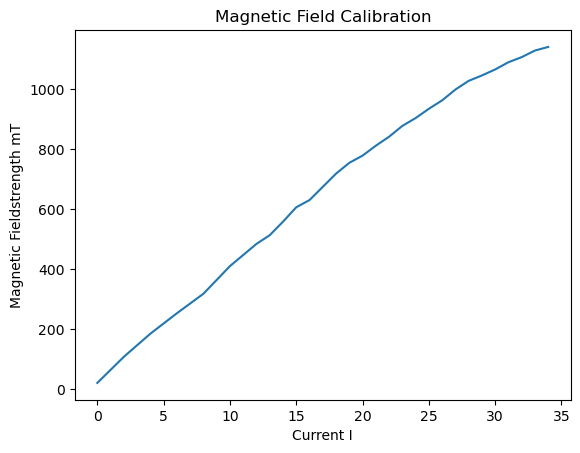

In [49]:
current, fieldstrength = read_mag_calib(file)

plt.plot(current, fieldstrength)  
plt.title("Magnetic Field Calibration")
plt.xlabel("Current I")
plt.ylabel("Magnetic Fieldstrength mT")
plt.show()

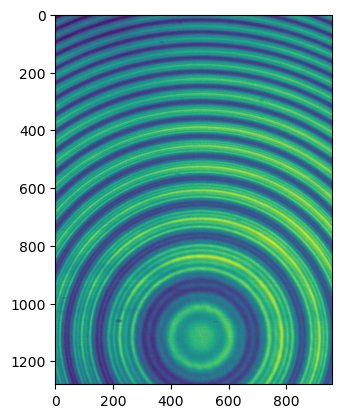

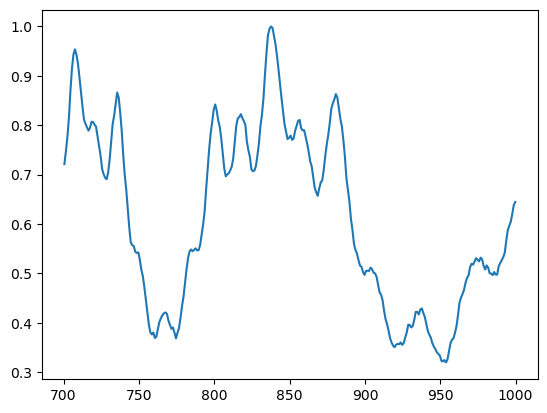

In [75]:
DarkFrame1 = "./Measurment Data/Dark Frames/2s1000F.dat"
DarkFrame2 = "./Measurment Data/Dark Frames/282ms500F.dat"
rings = "./Measurment Data/Green Line/Without Pol 27A.dat"

ImageData = read_image(rings) - read_image(DarkFrame2)
lineOut = image_line(ImageData, 490, 20)
lineOut_normal = lineOut / max(lineOut)


plt.imshow(ImageData)
plt.savefig('Image-DarkFrame.png')
plt.show()

x = np.linspace(0,len(lineOut),len(lineOut))
plt.plot(x[700:1000],lineOut_normal[700:1000])
plt.show()